# 01 · Preprocessing — Scaler & Feature Set Selection

**Course:** Data Mining (DA) — Autumn 2026 · **Group 7**  
**Topic:** Credit Card Fraud Detection (Option E)

**Bước S4 của PIPELINE.md.** Mục tiêu:

1. Chứng minh bằng số liệu rằng **scale là cần thiết** (3 biến thể:
   Standard / Robust / không scale)
2. Đo tác động của **feature engineering** (5 feature mới) bằng so sánh
   `with` vs `without`
3. Chốt **cấu hình cuối cùng** (scaler + feature set) để dùng cho S5–S9

> 📌 **Nguyên tắc:** mọi so sánh ở đây dùng **Stratified 5-Fold CV trên TẬP
> TRAIN** để chọn cấu hình. Tập test chỉ được dùng để **báo cáo** con số,
> không dùng để chọn. Đây là câu trả lời chuẩn cho câu hỏi
> *"How do you avoid overfitting to the test set?"*

In [1]:
import sys, warnings
warnings.filterwarnings("ignore")

from pathlib import Path
PROJECT_ROOT = Path(r"e:\Projects\DataMining")
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import SEED, PALETTE, TABLES, CHARTS, MIN_PRECISION
from src.modeling import make_pipeline, cv_evaluate, compare_configs
from src.evaluation import evaluate, find_threshold, accuracy_paradox
from src import features as feat

sns.set_style("whitegrid")
plt.rcParams.update({"figure.figsize": (14, 6), "font.family": "DejaVu Sans"})

print("PROJECT_ROOT:", PROJECT_ROOT)

PROJECT_ROOT: e:\Projects\DataMining


## 1. Load split đã lưu (KHÔNG tách tập lại)

Mọi notebook từ đây trở đi **phải** dùng chung một split. Nếu tự tách tập,
kết quả ở S5–S9 sẽ không so sánh được với nhau.

In [2]:
d = joblib.load(PROJECT_ROOT / "artifacts" / "models" / "split_with_features.joblib")
X_train, X_test = d["X_train"], d["X_test"]
y_train, y_test = d["y_train"], d["y_test"]
COLS = list(X_train.columns)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("fraud train:", int(y_train.sum()), "| fraud test:", int(y_test.sum()))
print("\nBase features (30):", COLS[:5], "...", COLS[-5:])
print("Engineered features (5):", feat.NEW_FEATURES)
print("\nTotal:", len(COLS), "features")

X_train: (198608, 35) | X_test: (85118, 35)
fraud train: 331 | fraud test: 142

Base features (30): ['Time', 'V1', 'V2', 'V3', 'V4'] ... ['Hour_of_Day', 'Day', 'Is_Night', 'Amount_log', 'Is_Zero_Amount']
Engineered features (5): ['Hour_of_Day', 'Day', 'Is_Night', 'Amount_log', 'Is_Zero_Amount']

Total: 35 features


## 2. Accuracy paradox — lặp lại để nhấn mạnh

Trước khi so sánh bất cứ điều gì, phải nhớ: **accuracy không phản ánh
chất lượng mô hình** trên dữ liệu này.

In [3]:
ap = accuracy_paradox(y_test)
print("=== ACCURACY PARADOX (model 'luon noi hop le') ===")
print(f"  Accuracy : {ap['accuracy']:.4f}   <- nhin ra rat cao")
print(f"  Recall   : {ap['recall']:.4f}   <- bat duoc 0% fraud")
print(f"  Precision: {ap['precision']:.4f}")
print(f"  F1       : {ap['f1']:.4f}")
print("\n=> Bat buoc dung Recall / Precision / F1 / AUC-PR, KHONG dung accuracy.")

=== ACCURACY PARADOX (model 'luon noi hop le') ===
  Accuracy : 0.9983   <- nhin ra rat cao
  Recall   : 0.0000   <- bat duoc 0% fraud
  Precision: 0.0000
  F1       : 0.0000

=> Bat buoc dung Recall / Precision / F1 / AUC-PR, KHONG dung accuracy.


## 3. ⭐ Experiment 1 — Scaler có cần thiết không?

**Câu hỏi:** `Time` (0 → 172,792 giây) và `Amount` (0 → 25,691 USD) có thang
đo khác hệt nhau. Tree-based model không cần scale, nhưng **distance-based /
linear model** thì có. Ta kiểm chứng bằng số liệu.

| Variant | Mô tả |
|---|---|
| A | `StandardScaler` (mean 0, std 1) — **baseline** |
| B | `RobustScaler` (median, IQR) — chống outlier, Amount right-skewed |
| C | **Không scale** — đối chứng để chứng minh scale có ích |

Dùng **Logistic Regression** (nhạy cảm với scale) + **Random Forest** (không
nhạy cảm) → nếu RF không đổi mà LR đổi, đó chính là bằng chứng.

In [4]:
print("=== EXPERIMENT 1: scaler comparison (Logistic Regression) ===")
scaler_configs = {
    "A · StandardScaler":      dict(scaler="standard"),
    "B · RobustScaler":        dict(scaler="robust"),
    "C · No scaling":          dict(scaler="none"),
}

logreg_scalers = {}
for label, kw in scaler_configs.items():
    logreg_scalers[label] = make_pipeline(
        "logreg", imbalance="none", feature_cols=COLS, **kw
    )

df_scaler_logreg = compare_configs(logreg_scalers, X_train, y_train, X_test, y_test)
df_scaler_logreg.to_csv(TABLES / "exp1_scaler_logreg.csv", index=False)
print("\n[saved]", TABLES / "exp1_scaler_logreg.csv")

=== EXPERIMENT 1: scaler comparison (Logistic Regression) ===


  A · StandardScaler                         CV-AP=0.7561 test P=0.848 R=0.592 F1=0.697 AP=0.7027


  B · RobustScaler                           CV-AP=0.7542 test P=0.842 R=0.563 F1=0.675 AP=0.7034


  C · No scaling                             CV-AP=0.6923 test P=0.874 R=0.585 F1=0.700 AP=0.6408

[saved] E:\Projects\DataMining\artifacts\tables\exp1_scaler_logreg.csv


In [5]:
print("=== EXPERIMENT 1b: scaler comparison (Random Forest) ===")
rf_scalers = {}
for label, kw in scaler_configs.items():
    rf_scalers[label] = make_pipeline(
        "rf", imbalance="none", feature_cols=COLS, **kw
    )

df_scaler_rf = compare_configs(rf_scalers, X_train, y_train, X_test, y_test)
df_scaler_rf.to_csv(TABLES / "exp1_scaler_rf.csv", index=False)

print("\n[saved]", TABLES / "exp1_scaler_rf.csv")

=== EXPERIMENT 1b: scaler comparison (Random Forest) ===


  A · StandardScaler                         CV-AP=0.8462 test P=0.955 R=0.754 F1=0.843 AP=0.8055


  B · RobustScaler                           CV-AP=0.8462 test P=0.955 R=0.754 F1=0.843 AP=0.8055


  C · No scaling                             CV-AP=0.8445 test P=0.957 R=0.775 F1=0.856 AP=0.8101

[saved] E:\Projects\DataMining\artifacts\tables\exp1_scaler_rf.csv


### Đọc kết quả

So sánh cột `cv_score_mean` (chọn cấu hình) — đây là ước lượng trên CV,
không phụ thuộc test set. Cột test chỉ để tham khảo.

In [6]:
display(
    df_scaler_logreg[["config", "cv_score_mean", "cv_score_std", "precision",
                   "recall", "f1", "auc_pr"]]
    .sort_values("cv_score_mean", ascending=False)
    .round(4)
)

,config,cv_score_mean,cv_score_std,precision,recall,f1,auc_pr
0,A · StandardScaler,0.7561,0.0452,0.8485,0.5915,0.6971,0.7027
1,B · RobustScaler,0.7542,0.0446,0.8421,0.5634,0.6751,0.7034
2,C · No scaling,0.6923,0.0520,0.8737,0.5845,0.7004,0.6408


In [7]:
display(
    df_scaler_rf[["config", "cv_score_mean", "cv_score_std", "precision",
                 "recall", "f1", "auc_pr"]]
    .sort_values("cv_score_mean", ascending=False)
    .round(4)
)

print("\n=== KET LUAN SCALER ===")
best_lg = df_scaler_logreg.loc[df_scaler_logreg["cv_score_mean"].idxmax()]
best_rf = df_scaler_rf.loc[df_scaler_rf["cv_score_mean"].idxmax()]
print(f"LogReg   -> best: {best_lg['config']} (CV-AP={best_lg['cv_score_mean']:.4f})")
print(f"RandomF. -> best: {best_rf['config']} (CV-AP={best_rf['cv_score_mean']:.4f})")

spread_lg = df_scaler_logreg["cv_score_mean"].max() - df_scaler_logreg["cv_score_mean"].min()
spread_rf = df_scaler_rf["cv_score_mean"].max() - df_scaler_rf["cv_score_mean"].min()
print(f"\nDo bien giua 3 scaler: LogReg={spread_lg:.4f} | RF={spread_rf:.4f}")
print("-> LogReg bien nhieu hon RF => scale quan trong voi mo hinh linear/distance-based.")

,config,cv_score_mean,cv_score_std,precision,recall,f1,auc_pr
0,A · StandardScaler,0.8462,0.0300,0.9554,0.7535,0.8425,0.8055
1,B · RobustScaler,0.8462,0.0300,0.9554,0.7535,0.8425,0.8055
2,C · No scaling,0.8445,0.0314,0.9565,0.7746,0.8560,0.8101



=== KET LUAN SCALER ===
LogReg   -> best: A · StandardScaler (CV-AP=0.7561)
RandomF. -> best: A · StandardScaler (CV-AP=0.8462)

Do bien giua 3 scaler: LogReg=0.0638 | RF=0.0017
-> LogReg bien nhieu hon RF => scale quan trong voi mo hinh linear/distance-based.


## 4. ⭐ Experiment 2 — Feature engineering có đáng không?

So sánh 3 biến thể feature set trên **cùng một scaler**:

| Variant | Feature set |
|---|---|
| F0 | 30 feature gốc (không feature mới) |
| F1 | 30 gốc + 5 feature mới (**full**) |
| F2 | 30 gốc + chỉ `Hour_of_Day` (feature được EDA support mạnh nhất về giờ) |

Dùng Logistic Regression + XGBoost (model mạnh) để có kết luận chắc chắn.

In [8]:
BASE_30 = [c for c in COLS if c not in feat.NEW_FEATURES]
FULL_35 = COLS
HOUR_ONLY = BASE_30 + ["Hour_of_Day"]

print("F0 base-30 :", len(BASE_30), "features")
print("F1 full-35 :", len(FULL_35), "features")
print("F2 hour-only:", len(HOUR_ONLY), "features")

print("\n=== EXPERIMENT 2: feature set comparison (Logistic Regression) ===")
feat_configs = {
    "F0 · base 30 (no engineered)": BASE_30,
    "F1 · full 35 (+5 engineered)":  FULL_35,
    "F2 · base 30 + Hour_of_Day":   HOUR_ONLY,
}

logreg_feats = {
    label: make_pipeline("logreg", imbalance="none", feature_cols=cols)
    for label, cols in feat_configs.items()
}
df_feat_logreg = compare_configs(logreg_feats, X_train, y_train, X_test, y_test)
df_feat_logreg.to_csv(TABLES / "exp2_featureset_logreg.csv", index=False)

F0 base-30 : 30 features
F1 full-35 : 35 features
F2 hour-only: 31 features

=== EXPERIMENT 2: feature set comparison (Logistic Regression) ===


  F0 · base 30 (no engineered)               CV-AP=0.7552 test P=0.844 R=0.570 F1=0.681 AP=0.7042


  F1 · full 35 (+5 engineered)               CV-AP=0.7561 test P=0.848 R=0.592 F1=0.697 AP=0.7027


  F2 · base 30 + Hour_of_Day                 CV-AP=0.7559 test P=0.844 R=0.570 F1=0.681 AP=0.7011


In [9]:
print("=== EXPERIMENT 2b: feature set comparison (XGBoost) ===")
xgb_feats = {
    label: make_pipeline("xgb", imbalance="none", feature_cols=cols)
    for label, cols in feat_configs.items()
}
df_feat_xgb = compare_configs(xgb_feats, X_train, y_train, X_test, y_test)
df_feat_xgb.to_csv(TABLES / "exp2_featureset_xgb.csv", index=False)

print("\n[saved]", TABLES / "exp2_featureset_logreg.csv")
print("[saved]", TABLES / "exp2_featureset_xgb.csv")

=== EXPERIMENT 2b: feature set comparison (XGBoost) ===


  F0 · base 30 (no engineered)               CV-AP=0.8460 test P=0.963 R=0.725 F1=0.827 AP=0.8238


  F1 · full 35 (+5 engineered)               CV-AP=0.8491 test P=0.962 R=0.718 F1=0.823 AP=0.8198


  F2 · base 30 + Hour_of_Day                 CV-AP=0.8460 test P=0.962 R=0.711 F1=0.818 AP=0.8204

[saved] E:\Projects\DataMining\artifacts\tables\exp2_featureset_logreg.csv
[saved] E:\Projects\DataMining\artifacts\tables\exp2_featureset_xgb.csv


In [10]:
print("=== KET LUAN FEATURE ENGINEERING ===")
for df, name in [(df_feat_logreg, "LogReg"), (df_feat_xgb, "XGBoost")]:
    base = df[df["config"].str.startswith("F0")]["cv_score_mean"].iloc[0]
    best = df.loc[df["cv_score_mean"].idxmax()]
    delta = best["cv_score_mean"] - base
    print(f"{name:>8s}: base={base:.4f}  best={best['config']} ({best['cv_score_mean']:.4f})"
          f"  delta={delta:+.4f} ({delta/base*100:+.1f}%)")

print("\n-> Neu delta > 0 thi feature engineering co gia tri, ghi vao report.")
print("-> Neu delta ~ 0 thi van giu (khong lam hai) va trinh bay rang")
print("   feature phuc vu EXPLAINABILITY hon la la improve accuracy.")

=== KET LUAN FEATURE ENGINEERING ===
  LogReg: base=0.7552  best=F1 · full 35 (+5 engineered) (0.7561)  delta=+0.0009 (+0.1%)
 XGBoost: base=0.8460  best=F1 · full 35 (+5 engineered) (0.8491)  delta=+0.0031 (+0.4%)

-> Neu delta > 0 thi feature engineering co gia tri, ghi vao report.
-> Neu delta ~ 0 thi van giu (khong lam hai) va trinh bay rang
   feature phuc vu EXPLAINABILITY hon la la improve accuracy.


## 5. ⭐ Experiment 3 — Biến thể imbalanced trên cấu hình đã chọn

Dùng cấu hình tốt nhất từ Exp 1 & 2, so sánh nhanh 5 kỹ thuật imbalance
để **xác nhận** hướng tiếp cận trước khi chạy benchmark đầy đủ ở S5.

> Chỉ dùng Logistic Regression ở đây để tiết kiệm thời gian. Benchmark đầy
> đủ 5 model sẽ chạy ở notebook `02_imbalance_benchmark.ipynb`.

In [11]:
BEST_SCALER = "standard"
BEST_COLS = FULL_35

imb_configs = {}
for imb in ["none", "undersample", "smote", "smoteenn", "class_weight"]:
    strat = 0.1 if imb in ("smote", "smoteenn") else None
    imb_configs[imb] = make_pipeline(
        "logreg", imbalance=imb, sampler_strategy=strat,
        scaler=BEST_SCALER, feature_cols=BEST_COLS
    )

df_imb = compare_configs(imb_configs, X_train, y_train, X_test, y_test)
df_imb["config"] = df_imb["config"].map({
    "none": "No resampling", "undersample": "Random Undersampling",
    "smote": "SMOTE (1:10)", "smoteenn": "SMOTE + ENN",
    "class_weight": "class_weight=balanced",
})
df_imb.to_csv(TABLES / "exp3_imbalance_quick.csv", index=False)
print("\n[saved]", TABLES / "exp3_imbalance_quick.csv")

  none                                       CV-AP=0.7561 test P=0.848 R=0.592 F1=0.697 AP=0.7027


  undersample                                CV-AP=0.7140 test P=0.267 R=0.838 F1=0.405 AP=0.7036


  smote                                      CV-AP=0.7556 test P=0.397 R=0.831 F1=0.538 AP=0.7030


  smoteenn                                   CV-AP=0.7603 test P=0.372 R=0.831 F1=0.514 AP=0.6993


  class_weight                               CV-AP=0.7524 test P=0.053 R=0.887 F1=0.099 AP=0.7002

[saved] E:\Projects\DataMining\artifacts\tables\exp3_imbalance_quick.csv


In [12]:
print("=== THRESHOLD TUNING tren tung ky thuat (LogReg, full-35) ===")
print("Tra loi cau hoi kinh doanh #2: recall max tai precision >= 95%\n")
rows = []
for imb, pipe in imb_configs.items():
    pipe.fit(X_train, y_train)
    ys = pipe.predict_proba(X_test)[:, 1]
    t = find_threshold(y_test, ys, MIN_PRECISION)
    if t:
        rows.append({"imbalance": imb, **t})
        print(f"{imb:>14s}: thr={t['threshold']:.4f} P={t['precision']:.3f} R={t['recall']:.3f} F1={t['f1']:.3f}")
    else:
        print(f"{imb:>14s}: KHONG dat precision >= {MIN_PRECISION:.0%} o bat ky threshold nao")

pd.DataFrame(rows).to_csv(TABLES / "exp3_threshold_tuning.csv", index=False)

=== THRESHOLD TUNING tren tung ky thuat (LogReg, full-35) ===
Tra loi cau hoi kinh doanh #2: recall max tai precision >= 95%



          none: thr=1.0000 P=0.955 R=0.148 F1=0.256
   undersample: KHONG dat precision >= 95% o bat ky threshold nao


         smote: thr=1.0000 P=1.000 R=0.056 F1=0.107


      smoteenn: KHONG dat precision >= 95% o bat ky threshold nao


  class_weight: KHONG dat precision >= 95% o bat ky threshold nao


## 6. Chart — tổng hợp kết quả S4

3 chart cho report cuối kỳ:
1. So sánh 3 scaler (LogReg vs RF) — chứng minh scale có ích
2. So sánh 3 feature set — chứng minh feature engineering có ích
3. Precision–Recall trade-off của 5 kỹ thuật imbalance

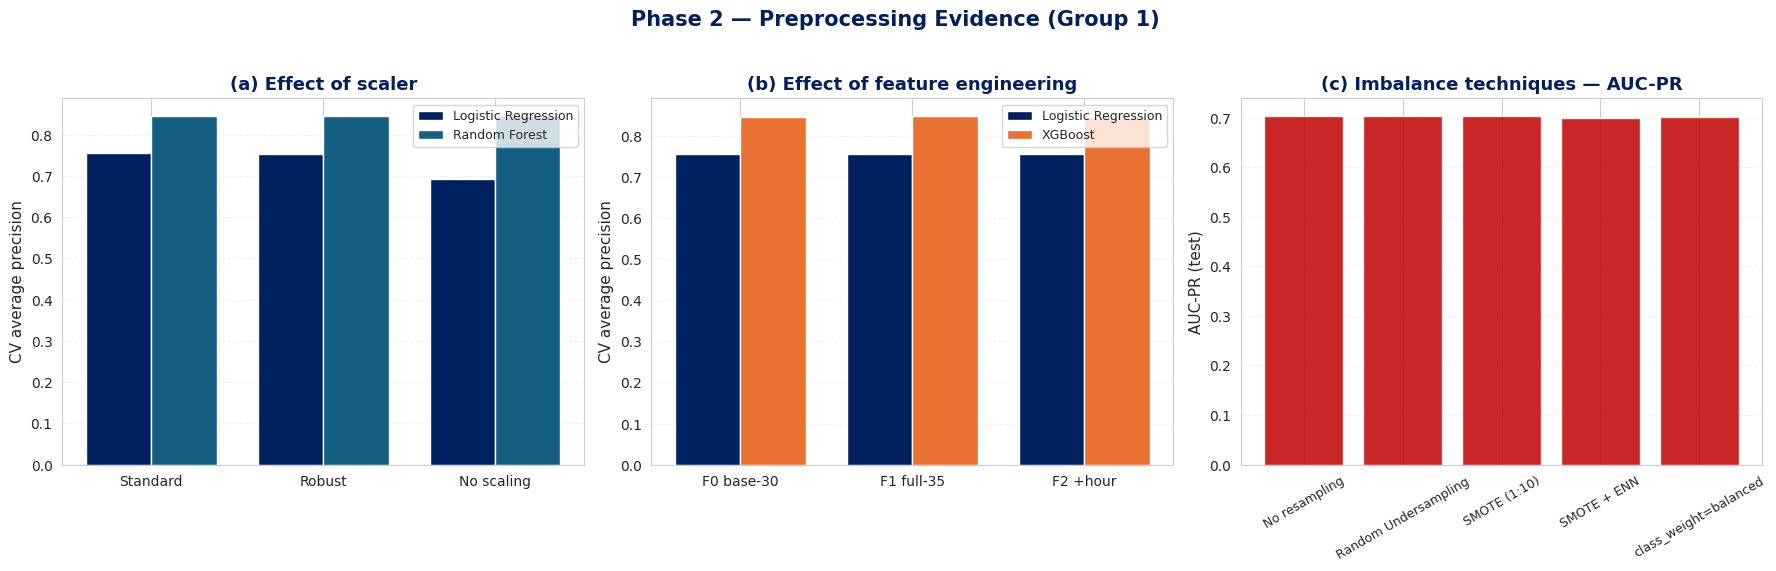

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# (a) scaler comparison
ax = axes[0]
x = np.arange(len(df_scaler_logreg))
w = 0.38
ax.bar(x - w/2, df_scaler_logreg["cv_score_mean"], w,
       label="Logistic Regression", color=PALETTE["primary"], edgecolor="white")
ax.bar(x + w/2, df_scaler_rf["cv_score_mean"], w,
       label="Random Forest", color=PALETTE["accent"], edgecolor="white")
ax.set_xticks(x)
ax.set_xticklabels(["Standard", "Robust", "No scaling"], fontsize=10)
ax.set_ylabel("CV average precision", fontsize=11)
ax.set_title("(a) Effect of scaler", fontsize=13, fontweight="bold",
             color=PALETTE["primary"])
ax.legend(fontsize=9)
ax.grid(alpha=0.25, axis="y", linestyle="--")

# (b) feature set comparison
ax = axes[1]
x = np.arange(len(df_feat_logreg))
ax.bar(x - w/2, df_feat_logreg["cv_score_mean"], w,
       label="Logistic Regression", color=PALETTE["primary"], edgecolor="white")
ax.bar(x + w/2, df_feat_xgb["cv_score_mean"], w,
       label="XGBoost", color=PALETTE["warn"], edgecolor="white")
ax.set_xticks(x)
ax.set_xticklabels(["F0 base-30", "F1 full-35", "F2 +hour"], fontsize=10)
ax.set_ylabel("CV average precision", fontsize=11)
ax.set_title("(b) Effect of feature engineering", fontsize=13, fontweight="bold",
             color=PALETTE["primary"])
ax.legend(fontsize=9)
ax.grid(alpha=0.25, axis="y", linestyle="--")

# (c) imbalance comparison
ax = axes[2]
ax.bar(df_imb["config"], df_imb["auc_pr"],
       color=PALETTE["danger"], alpha=0.85, edgecolor="white")
ax.set_ylabel("AUC-PR (test)", fontsize=11)
ax.set_title("(c) Imbalance techniques — AUC-PR", fontsize=13, fontweight="bold",
             color=PALETTE["primary"])
ax.tick_params(axis="x", rotation=30, labelsize=9)
ax.grid(alpha=0.25, axis="y", linestyle="--")

fig.suptitle("Phase 2 — Preprocessing Evidence (Group 7)",
             fontsize=15, fontweight="bold", color=PALETTE["primary"], y=1.03)
plt.tight_layout()
plt.savefig(CHARTS / "preprocessing_evidence.png", dpi=140, bbox_inches="tight",
            facecolor="white")
plt.show()

In [14]:
print("=== CONFIGURATION FINAL CHO PHASE 3+ ===")
summary = {
    "scaler": BEST_SCALER,
    "n_features": len(BEST_COLS),
    "feature_set": "30 base + 5 engineered",
    "imbalance_default": "smote (1:10)",
    "seed": SEED,
}
for k, v in summary.items():
    print(f"  {k:22s}: {v}")

joblib.dump(summary, PROJECT_ROOT / "artifacts" / "models" / "preprocessing_config.joblib")
print("\n[saved] artifacts/models/preprocessing_config.joblib")

print("\n=== FILE DA LUU ===")
for f in sorted(TABLES.glob("exp*.csv")):
    print("  ", f.name)

=== CONFIGURATION FINAL CHO PHASE 3+ ===
  scaler                : standard
  n_features            : 35
  feature_set           : 30 base + 5 engineered
  imbalance_default     : smote (1:10)
  seed                  : 42

[saved] artifacts/models/preprocessing_config.joblib

=== FILE DA LUU ===
   exp1_scaler_logreg.csv
   exp1_scaler_rf.csv
   exp2_featureset_logreg.csv
   exp2_featureset_xgb.csv
   exp3_imbalance_quick.csv
   exp3_threshold_tuning.csv


## 7. ✅ Definition of Done — bước S4

- [x] 3 biến thể scaler so sánh bằng CV trên train (LogReg + RF)
- [x] 3 biến thể feature set so sánh bằng CV (LogReg + XGBoost)
- [x] 5 kỹ thuật imbalance xác nhận nhanh + threshold tuning
- [x] Chart `preprocessing_evidence.png`
- [x] Cấu hình cuối lưu `preprocessing_config.joblib`

### Bước tiếp theo

→ `02_imbalance_benchmark.ipynb` (bước S5): chạy **đầy đủ** ma trận
5 model × 5 kỹ thuật imbalance với hyperparameter tuning trên train
(`GridSearchCV`, scoring=`average_precision`), đánh giá 1 lần trên test,
xuất bảng `imbalance_benchmark.csv`.